In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import joblib

from pathlib import Path
from lightgbm import LGBMRegressor, early_stopping, log_evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully")


Libraries imported successfully


In [2]:
DATA_PATH = Path("../data/processed")

train_df = pd.read_csv(DATA_PATH / "train.csv")
val_df = pd.read_csv(DATA_PATH / "validation.csv")
test_df = pd.read_csv(DATA_PATH / "test.csv")

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (2107, 18)
Validation: (452, 18)
Testing: (452, 18)


In [10]:
def prepare_data(data):
    data = data.copy()

    data["Open_Rel"] = data["Open"] / data["Close"] - 1
    data["High_Rel"] = data["High"] / data["Close"] - 1
    data["Low_Rel"] = data["Low"] / data["Close"] - 1

    data["SMA7_Rel"] = data["SMA_7"] / data["Close"] - 1
    data["SMA14_Rel"] = data["SMA_14"] / data["Close"] - 1

    data["MACD_Rel"] = data["MACD"] / data["Close"]
    data["MACD_Signal_Rel"] = data["MACD_Signal"] / data["Close"]

    data["Lag1_Rel"] = data["Lag_1"] / data["Close"] - 1
    data["Lag2_Rel"] = data["Lag_2"] / data["Close"] - 1
    data["Lag3_Rel"] = data["Lag_3"] / data["Close"] - 1

    data["Log_Volume"] = np.log1p(data["Volume"].clip(lower=0))

    data["Target_Return"] = data["Target"] / data["Close"] - 1

    return data


train_df = prepare_data(train_df)
val_df = prepare_data(val_df)
test_df = prepare_data(test_df)

print(train_df[["Close", "Target", "Target_Return"]].head())

        Close      Target  Target_Return
0  735.070007  727.830017      -0.009849
1  727.830017  745.049988       0.023659
2  745.049988  756.130005       0.014872
3  756.130005  754.010010      -0.002804
4  754.010010  771.400024       0.023063


In [11]:
FEATURES = [
    "Open_Rel", "High_Rel", "Low_Rel",
    "Return", "Volatility_7",
    "SMA7_Rel", "SMA14_Rel",
    "RSI_14", "MACD_Rel", "MACD_Signal_Rel",
    "Lag1_Rel", "Lag2_Rel", "Lag3_Rel",
    "Volume_Change", "Log_Volume"
]

X_train = train_df[FEATURES].replace([np.inf, -np.inf], np.nan)
X_val = val_df[FEATURES].replace([np.inf, -np.inf], np.nan)
X_test = test_df[FEATURES].replace([np.inf, -np.inf], np.nan)

y_train = train_df["Target_Return"]
y_val = val_df["Target_Return"]
y_test = test_df["Target_Return"]

# Fill missing feature values using training medians
medians = X_train.median()

X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)
X_test = X_test.fillna(medians)

print("Features:", len(FEATURES))
print("Missing values:", X_train.isnull().sum().sum())

Features: 15
Missing values: 0


In [12]:
model = LGBMRegressor(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    reg_lambda=1.0,
    random_state=42,
    verbosity=-1
)

start_time = time.time()

model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="rmse",
    callbacks=[
        early_stopping(stopping_rounds=50, verbose=True),
        log_evaluation(period=100)
    ]
)

training_time = time.time() - start_time

print("Training time:", round(training_time, 2), "seconds")
print("Best iteration:", model.best_iteration_)

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[16]	valid_0's rmse: 0.0376095	valid_0's l2: 0.00141448
Training time: 0.13 seconds
Best iteration: 16


c:\Users\SHUBA\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


In [13]:
pred_return = model.predict(
    X_test,
    num_iteration=model.best_iteration_
)

y_pred = test_df["Close"].to_numpy() * (1 + pred_return)
y_actual = test_df["Target"].to_numpy()

print("Actual prices:", y_actual[:5])
print("Predicted prices:", y_pred[:5])

Actual prices: [40254.54649816 38356.43950662 35566.65594049 37316.35939997
 39187.32812109]
Predicted prices: [40648.6655607  40114.70111537 38121.2308985  35348.55478859
 37636.86757162]


In [14]:
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
mape = np.mean(np.abs((y_actual - y_pred) / y_actual)) * 100
r2 = r2_score(y_actual, y_pred)

print("LightGBM Test Results")
print("---------------------")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")
print(f"R2:   {r2:.4f}")

LightGBM Test Results
---------------------
MAE:  1444.1175
RMSE: 1943.8558
MAPE: 3.45%
R2:   0.9704


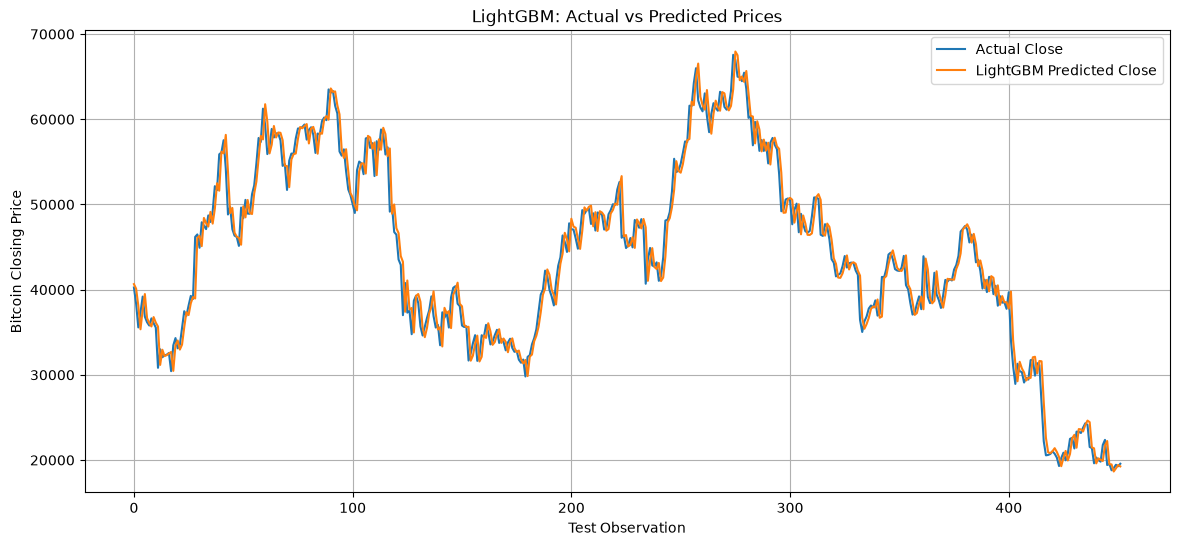

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(y_actual, label="Actual Close")
plt.plot(y_pred, label="LightGBM Predicted Close")

plt.xlabel("Test Observation")
plt.ylabel("Bitcoin Closing Price")
plt.title("LightGBM: Actual vs Predicted Prices")
plt.legend()
plt.grid(True)
plt.show()

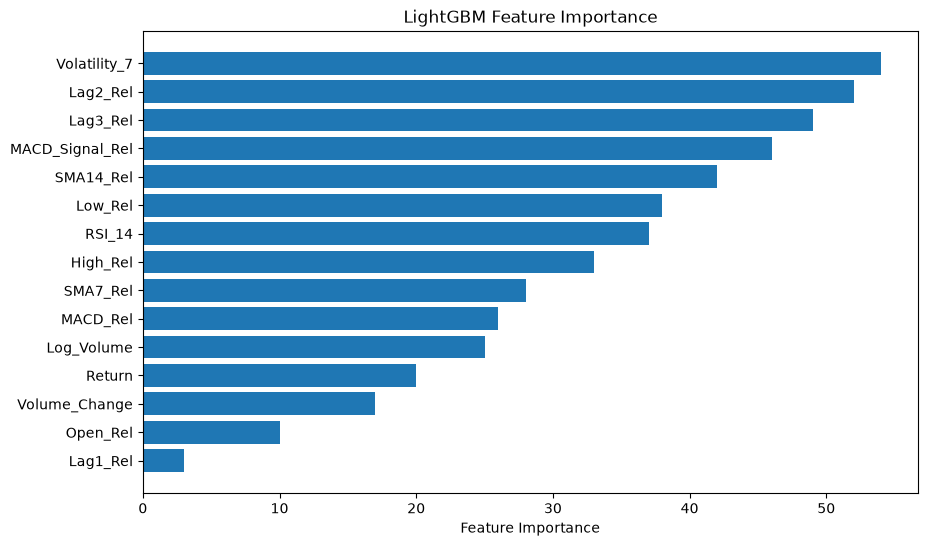

,Feature,Importance
4,Volatility_7,54
11,Lag2_Rel,52
12,Lag3_Rel,49
9,MACD_Signal_Rel,46
6,SMA14_Rel,42
2,Low_Rel,38
7,RSI_14,37
1,High_Rel,33
5,SMA7_Rel,28
8,MACD_Rel,26


In [16]:
importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("LightGBM Feature Importance")
plt.show()

display(importance_df)

In [17]:
MODEL_PATH = Path("../models")
RESULTS_PATH = Path("../results")

MODEL_PATH.mkdir(parents=True, exist_ok=True)
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

joblib.dump(model, MODEL_PATH / "lightgbm_return_model.pkl")

predictions_df = pd.DataFrame({
    "Date": test_df["Date"],
    "Actual_Close": y_actual,
    "LightGBM_Prediction": y_pred
})

predictions_df.to_csv(
    RESULTS_PATH / "lightgbm_predictions.csv",
    index=False
)

metrics_df = pd.DataFrame([{
    "Model": "LightGBM",
    "MAE": mae,
    "RMSE": rmse,
    "MAPE": mape,
    "R2": r2,
    "Training_Time_Seconds": training_time
}])

metrics_df.to_csv(
    RESULTS_PATH / "lightgbm_metrics.csv",
    index=False
)

print("LightGBM results saved successfully.")

LightGBM results saved successfully.
